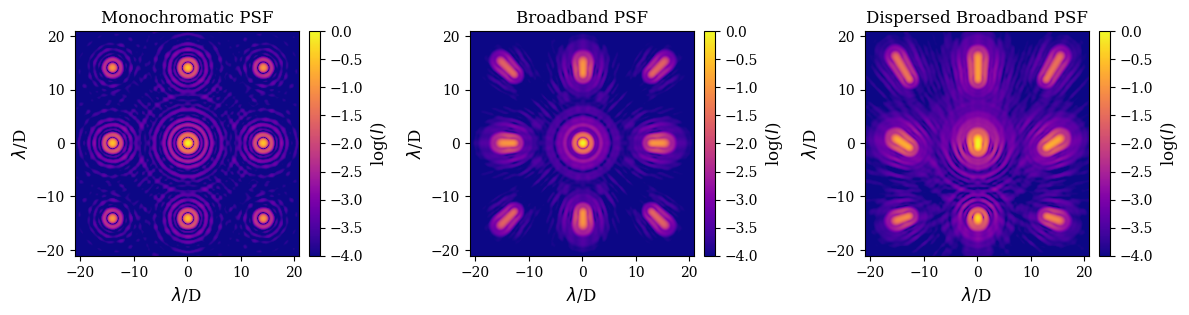

In [ ]:
import sys
import os

import numpy as np
from hcipy import *
import matplotlib.pyplot as plt

import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), 'simulations')))
from psfGenerator import PsfGenerator

def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

wavelength = 615E-9
wavelength_normalized = wavelength / 656E-9
grating_angle = 0
grating_frequency = 15


mono_bw = 1E-9
bb_bw = 110E-9

#making the figure for the paper (redoing the one from the SPIE proceeding)
color = 'plasma'

PsfGen_mono = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=mono_bw/wavelength, focal_sampling=6,focal_extent = grating_frequency*1.4, grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)
PsfGen_broad = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent = grating_frequency*1.4,grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)

psf_mono = PsfGen_mono.psf()
psf_bb = PsfGen_broad.psf()
psf_disp = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.1)

# center_of_intensity = np.array([sum(psf_bb*psf_bb.grid.x)/sum(psf_bb),sum(psf_bb*psf_bb.grid.y)/sum(psf_bb)])
# mask_ap = make_circular_aperture(30,center_of_intensity)
# mask = mask_ap(psf_bb.grid)
# mask = abs(mask - 1)
# psf_bb = mask * psf_bb
# psf_disp = mask * psf_disp

psf_mono = np.log10(PsfGen_mono.psf()) 
psf_bb = np.log10(PsfGen_broad.psf())
psf_disp = np.log10(PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.1))

# psf_mono /= max(psf_mono)
# psf_bb /= max(psf_bb)
# psf_disp /= max(psf_disp)

fig = plt.figure()
# colorbarpsf = imshow_field(psf_bb,cmap=color,vmin=-5)
# fig.colorbar(colorbarpsf,ax=axs,orientation='vertical',fraction=0.046,pad=0.04)

plt.subplot(1,3,1)
c = imshow_field(psf_mono,cmap=color,vmin=-4)
plt.title('Monochromatic PSF')
plt.xlabel(r'$\lambda$/D')
plt.ylabel(r'$\lambda$/D')
plt.subplot(1,3,2)
a = imshow_field(psf_bb,cmap=color,vmin=-4)
plt.title('Broadband PSF')
plt.xlabel(r'$\lambda$/D')
plt.ylabel(r'$\lambda$/D')
plt.subplot(1,3,3)
b = imshow_field(psf_disp,cmap=color,vmin=-4)
plt.xlabel(r'$\lambda$/D')
plt.ylabel(r'$\lambda$/D')
#plt.yticks([])
plt.title('Dispersed Broadband PSF')

ca = colorbar(a)
cb = colorbar(b)
cc = colorbar(c)

ca.set_label(r'log($I$)')
cb.set_label(r'log($I$)')
cc.set_label(r'log($I$)')

plt.tight_layout(h_pad=1)
plt.show()

In [ ]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/dispersion_sparkles.png',dpi=300)